In [28]:
import os
import scanpy as sc
import matplotlib.pyplot as plt

In [29]:
in_dir = "../../results/03_kidney_atlas/08_merge_celltypes"
out_dir = "../../results/03_kidney_atlas/12_viz_gene"
os.makedirs(out_dir, exist_ok=True)

In [30]:
adata = sc.read(f"{in_dir}/adata.h5ad")

In [31]:
adata

AnnData object with n_obs × n_vars = 200338 × 29732
    obs: 'library', 'nCount_RNA', 'nFeature_RNA', 'percent.er', 'percent.mt', 'degen.score', 'aEpi.score', 'aStr.score', 'cyc.score', 'matrisome.score', 'collagen.score', 'glycoprotein.score', 'proteoglycan.score', 'S.Score', 'G2M.Score', 'Phase', 'experiment', 'experiment.short', 'specimen', 'condition.long', 'condition.l1', 'condition.l2', 'condition.l3', 'patient', 'region.l1', 'region.l2', 'percent.cortex', 'percent.medulla', 'sex', 'race', 'tissue_type', 'assay', 'location', 'laterality', 'snDrop_predicted_subclass', 'snDrop_prediction_score', 'pagoda_k50_infomap', 'pagoda_k100_infomap', 'pagoda_k200_infomap', 'pagoda_k500_infomap', 'clusters', 'subclass.full', 'subclass.l3', 'subclass.l2', 'subclass.l1', 'state.l2', 'state.l1', 'class', 'structure', 'cell_type'
    var: 'genes'
    uns: 'cell_type_colors', 'condition.l3_colors', 'laterality_colors', 'location_colors', 'patient_colors', 'structure_colors', 'subclass.l1_colors', '

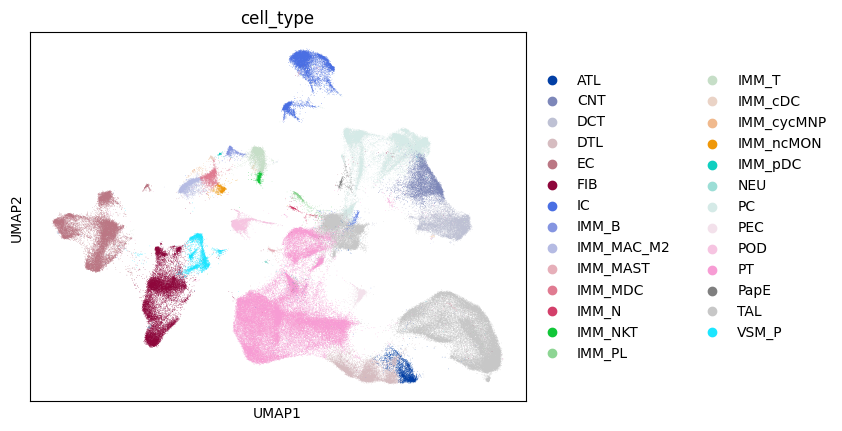

In [32]:
sc.pl.umap(adata, color="cell_type")

In [33]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

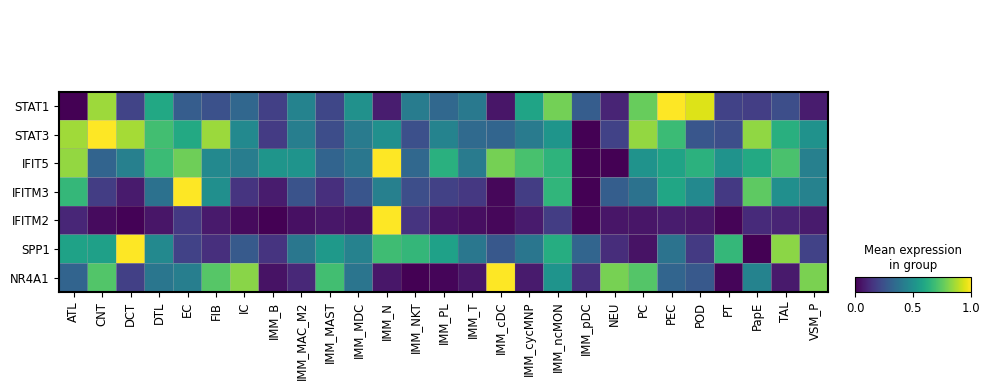

In [34]:
fig, ax = plt.subplots(figsize=(10, 4))

sc.pl.matrixplot(adata, 
             var_names=["STAT1", "STAT3", #"IRF9",
                        "IFIT5", "IFITM3", "IFITM2",
                        "SPP1", "NR4A1"], 
             use_raw=False,
             standard_scale="var",
             groupby="cell_type",
             ax=ax, swap_axes=True,
             show=False)
plt.tight_layout()
plt.savefig(f"{out_dir}/other_genes.png")

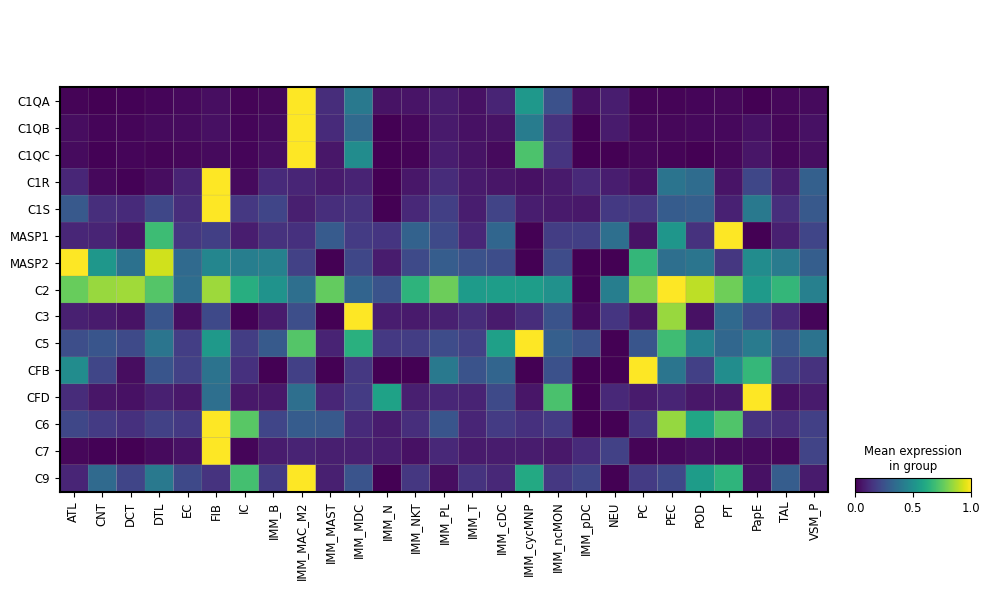

In [35]:
fig, ax = plt.subplots(figsize=(10, 6))

sc.pl.matrixplot(adata, 
             var_names=["C1QA", "C1QB", "C1QC",
                        "C1R", "C1S",
                        "MASP1", "MASP2", "C2", "C3", "C5", 
                        "CFB", "CFD", "C6", "C7", "C9"], 
             use_raw=False,
             standard_scale="var",
             groupby="cell_type",
             ax=ax, swap_axes=True,
             show=False)
plt.tight_layout()
plt.savefig(f"{out_dir}/complement_genes.png")